# 11 · Frozen churn model explainability

**Internal diagnostic research · Fieldwise Cloud fictional development evidence**

One canonical contractual episode at a UTC observation is the prediction unit.
The experimental outcome is confirmed contractual churn within 30 days. Eight
validation accounts had a positive outcome. AP was 0.01138, ROC-AUC 0.23272,
and 695 of 703 threshold alerts were false positives. This notebook
investigates score behaviour, synthetic patterns and prediction failures.
Operational customer risk and retention priorities are outside scope.

The frozen pipeline and approved Phase 09 protocol define the output and
cohorts. All research figures use a verified local report. The notebook
performs no fitting, explanation generation or reserve inference.
[Phase 09 scope](../../docs/05_ml/phase09_explainability_scope_and_validation.md)
and [accepted churn protocol](../../docs/05_ml/phase06_churn_evaluation_protocol.md).

In [ ]:
from os import getenv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter

from nowa_customer_intelligence.explainability.research import WORKSPACE, load_report

model = "churn"
root = next(
    path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file()
)
requested = getenv("NCI_XAI_WORKSPACE")
workspace = Path(requested) if requested else root / WORKSPACE
r = load_report(workspace, model) if requested or workspace.exists() else None
plt.rcParams.update(
    {
        "figure.figsize": (10, 4.4),
        "figure.dpi": 125,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.20,
        "axes.axisbelow": True,
    }
)
blue, warm, grey = "#246782", "#a44d28", "#65757b"
cadence_colours = {"monthly": blue, "annual": warm, "mixed": "#694b85"}
footer = (
    "Fieldwise development · AP 0.01138 · ROC-AUC 0.23272 · 8 positive accounts"
    " · weak predictive validity"
)
units = "Probability" if model == "churn" else "Gross issued GBP"


def show(fig):
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.text(0.015, 0.015, footer, fontsize=8, color=grey)
    plt.show()
    plt.close(fig)


def readable(name):
    return name.replace("_", " ")

## Research dashboard and frozen evidence

The accepted design and model checksums precede unpickling in the research
runner. Input populations stay anchored to the accepted development evidence.
The dashboard distinguishes row counts from independent account counts.
Positive outcome support matters when interpreting classification error.
Clustering and protected reserves are outside this report.

In [ ]:
if r:
    population = pd.DataFrame(r["reference_populations"]).T
    display(population[["rows", "accounts", "cadence", "month"]])
    display(pd.Series(r["model"], name="Frozen model evidence").to_frame())
    display(pd.Series(r["accepted_metrics"], name="Retained validation evidence").to_frame())
    display(pd.Series(r["environment"]["packages"], name="Research environment").to_frame())
    display(
        Markdown(
            f"**Primary explanation** · {r['primary']['method']} · {r['primary']['scale']}. "
            f"**Protocol SHA-256** · `{r['protocol_sha256']}`."
        )
    )
else:
    display(
        Markdown(
            "A verified Phase 09 research report is required for empirical results. "
            "The notebook README gives the isolated replay command."
        )
    )

,rows,accounts,cadence,month
training,4254,397,"{'monthly': 3204, 'annual': 1050}","{'2021-06': 4, '2021-07': 22, '2021-08': 48, '..."
validation,717,205,"{'monthly': 560, 'annual': 157}","{'2023-04': 163, '2023-05': 174, '2023-06': 18..."
explained_global,96,96,"{'monthly': 76, 'annual': 20}","{'2023-04': 1, '2023-05': 2, '2023-06': 1, '20..."


,Frozen model evidence
name,churn
sha256,16d7a588ec36dc4b22beb20b56f98903af68d445356392...
identifier,Gradient Boosting 15 leaves balanced
registry,fieldwise-episode-features-v1
class,HistGradientBoostingClassifier
steps,"[ColumnTransformer, VarianceThreshold, HistGra..."
input_hashes,{'bundle_manifest': '3f5f1e4768cd6965e6c900288...
threshold,0.003965


,Retained validation evidence
rows,717.000000
positives,8.000000
prevalence,0.011158
average_precision,0.011380
roc_auc,0.232722
precision,0.011380
recall,1.000000
f1,0.022504
brier,0.042733
tn,14.000000


,Research environment
numpy,2.5.4
scikit-learn,1.9.1
shap,0.54.1
numba,0.68.1
joblib,1.6.0
scipy,1.18.1
pandas,2.3.3


**Primary explanation** · interventional TreeSHAP grouped to original features · class-1 probability. **Protocol SHA-256** · `3ac69edf68f504074d7d0b958a9a936aa82379142bdbb2c20f16abfee0417926`.

## Preprocessing, feature dictionary and positional lineage

**Frozen raw registry → fitted numerical imputer and categorical encoder →
fitted selection where present → frozen tree estimator → output contract.**
The original field table records provenance and missingness conventions.
The transformation table follows physical positions, including separate
dummies and indicators. Collapsing a fitted transformed explanation uses
a signed sum of coordinates that originated in the same field.

For example, a missingness flag and the imputed numerical coordinate can
represent one original measure. Signed contributions +0.06 and −0.02 yield
+0.04 under that mapping. A separate game on the raw feature blocks uses
a different set of coalitions.

,feature,group,type,nullable,missing,calculation
0,episode_age_days,episode,int,False,0,Whole UTC days since establishment.
1,prior_completed_episodes,customer_history,int,False,0,Earlier episodes with established and terminated facts known by observation.
2,plan_id,commercial,str,False,0,Latest usable snapshot plan.
3,billing_frequency,commercial,str,False,0,Latest usable snapshot cadence.
4,monthly_recurring_gbp,commercial,Decimal,False,0,Latest usable snapshot monthly-normalised GBP.
5,issued_invoice_count,billing,int,False,0,Count of available issued charges.
6,issued_amount_gbp,billing,Decimal,True,3020,"Sum of available issued amounts, missing if none."
7,mean_invoice_gbp,billing,Decimal,True,3020,"Mean available issued amount rounded to pennies, missing if none."
8,days_since_last_invoice,billing,int,True,3020,"Whole UTC days since latest available issue date, missing if none."
9,expected_usage_months,coverage,int,False,0,Whole UTC months in scope.


,transformed,original,component,retained,position
0,numeric__episode_age_days,episode_age_days,numerical,True,1
1,numeric__prior_completed_episodes,prior_completed_episodes,numerical,True,2
2,numeric__monthly_recurring_gbp,monthly_recurring_gbp,numerical,True,3
3,numeric__issued_invoice_count,issued_invoice_count,numerical,True,4
4,numeric__issued_amount_gbp,issued_amount_gbp,numerical,True,5
5,numeric__mean_invoice_gbp,mean_invoice_gbp,numerical,True,6
6,numeric__days_since_last_invoice,days_since_last_invoice,numerical,True,7
7,numeric__expected_usage_months,expected_usage_months,numerical,True,8
8,numeric__observed_usage_months,observed_usage_months,numerical,True,9
9,numeric__unobserved_usage_months,unobserved_usage_months,numerical,False,10


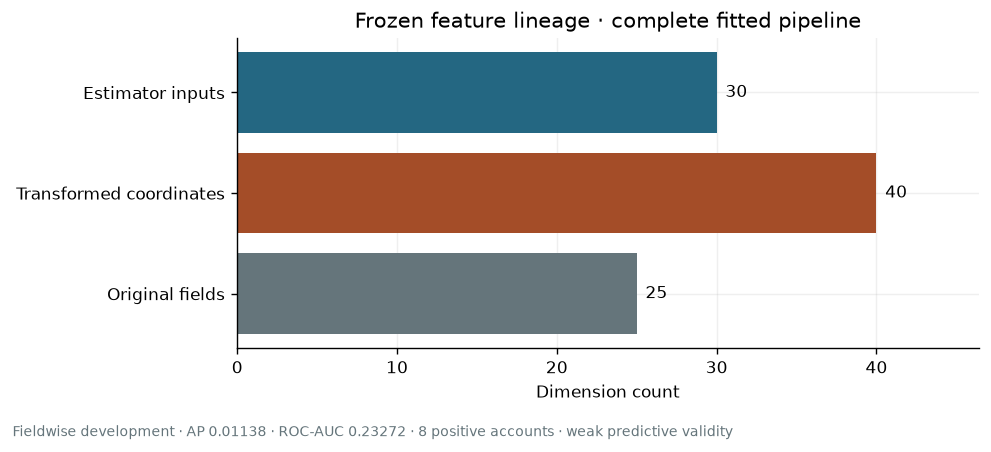

In [ ]:
if r:
    dictionary = pd.DataFrame(r["feature_dictionary"])
    lineage = pd.DataFrame(r["lineage"])
    widths = r["compatibility"]["prediction_contract"]["widths"]
    with pd.option_context("display.max_rows", 55, "display.max_colwidth", 85):
        display(dictionary)
        display(lineage.assign(position=np.arange(len(lineage)) + 1))
    fig, ax = plt.subplots(figsize=(8, 3.6))
    names = ["Original fields", "Transformed coordinates", "Estimator inputs"]
    bars = ax.barh(names, widths, color=[grey, warm, blue])
    ax.bar_label(bars, padding=5)
    ax.set(
        title="Frozen feature lineage · complete fitted pipeline",
        xlabel="Dimension count",
        xlim=(0, max(widths) * 1.16),
    )
    show(fig)

## Churn score, output scales and historical errors

For log-odds margin $m(x)$, the fitted class-1 probability is
$p(x)=1/(1+\exp[-m(x)])$. For example, an illustrative margin
$\log(1/3)$ gives 0.25. Apply the logistic transform to the base
plus the sum of log-odds contributions. Probability contributions
must come from a probability-scale explanation.

The original threshold is inclusive and was chosen on development
validation. It alerts on 703 rows, including eight positives.
Plotting counts and the low threshold makes the false-positive burden
visible. An exact local score explanation leaves those errors intact.

,Validation prediction audit
widths,"[25, 40, 30]"
validation_rows,717
raw_pipeline_max_error,0.0
linked_or_retained_max_error,0.0
validation_raw_negative,None


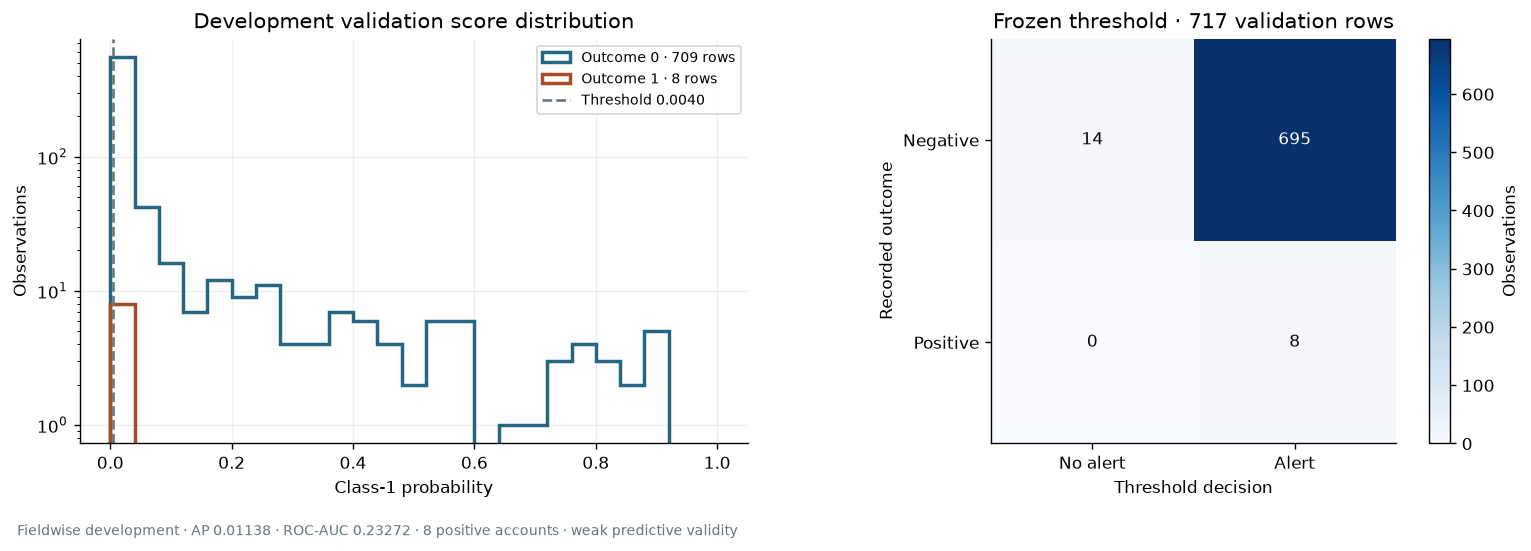

In [ ]:
if r:
    dist = pd.DataFrame(r["distribution"])
    contract = r["compatibility"]["prediction_contract"]
    display(pd.Series(contract, name="Validation prediction audit").to_frame())
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
    if model == "churn":
        threshold = r["model"]["threshold"]
        edges = np.linspace(0, 1, 26)
        for actual, plot_colour in ((0, blue), (1, warm)):
            frame = dist.loc[dist.target.eq(actual), "prediction"]
            axes[0].hist(
                frame,
                bins=edges,
                histtype="step",
                lw=2,
                color=plot_colour,
                label=f"Outcome {actual} · {len(frame)} rows",
            )
        axes[0].axvline(threshold, ls="--", color=grey, label=f"Threshold {threshold:.4f}")
        axes[0].set(
            title="Development validation score distribution",
            xlabel="Class-1 probability",
            ylabel="Observations",
            yscale="log",
        )
        axes[0].legend(fontsize=8)
        m = r["accepted_metrics"]
        counts = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
        image = axes[1].imshow(counts, cmap="Blues")
        for (row, col), value in np.ndenumerate(counts):
            axes[1].text(
                col,
                row,
                str(value),
                ha="center",
                va="center",
                color="white" if value > counts.max() / 2 else "black",
            )
        axes[1].set(
            title="Frozen threshold · 717 validation rows",
            xlabel="Threshold decision",
            ylabel="Recorded outcome",
            xticks=[0, 1],
            xticklabels=["No alert", "Alert"],
            yticks=[0, 1],
            yticklabels=["Negative", "Positive"],
        )
        axes[1].grid(False)
        fig.colorbar(image, ax=axes[1], label="Observations")
    else:
        for name, group in dist.groupby("cadence"):
            axes[0].scatter(
                group.target,
                group.prediction,
                s=18,
                alpha=0.46,
                color=cadence_colours[name],
                label=f"{name} · {len(group)}",
            )
        boundary = max(dist.target.max(), dist.prediction.max())
        axes[0].plot([0, boundary], [0, boundary], ls="--", color=grey, label="Perfect agreement")
        axes[0].set(
            title="Observed issuance and frozen forecast",
            xlabel="Actual gross issued GBP",
            ylabel="Clipped prediction GBP",
        )
        axes[0].legend(fontsize=8)
        axes[1].hist(dist.error, bins=25, color=blue)
        axes[1].axvline(0, ls="--", color=grey)
        axes[1].set(
            title="Signed prediction errors · 355 validation rows",
            xlabel="Prediction minus actual GBP",
            ylabel="Observations",
        )
    show(fig)

if r and model == "clv":
    negative = dist.loc[dist.raw.lt(0), ["cadence", "raw", "prediction"]]
    display(
        negative.rename(columns={"raw": "Pre-clip GBP", "prediction": "Final GBP"}).reset_index(
            drop=True
        )
    )
    display(
        Markdown(
            f"Clipping changed **{len(negative)}** validation predictions. "
            "Each became zero under the accepted output rule."
        )
    )

## Training-only background and explanation observations

The reference uses up to 64 distinct training accounts. Each contributes
one latest eligible row, with a stable episode tie-break where needed.
Proportionate cadence quotas and seed 909 fix the background. The 96
global explanation rows are account-balanced on the previously evaluated
validation population, with a fixed seed and cadence quotas. Local roles
are selected separately and only the global sample enters global means.

Using the latest fitting row per account concentrates the background near
the end of training. This is a defined reference distribution. Compare
against alternatives within the same authorised training population.

,Reference background
rows,64
accounts,64
cadence,"{'monthly': 48, 'annual': 16}"
month,"{'2022-12': 1, '2023-01': 2, '2023-02': 61}"
seed,909
sha256,59b8d19a3c0498082a1a4f3229b2d0edeb956ce756d0a0...


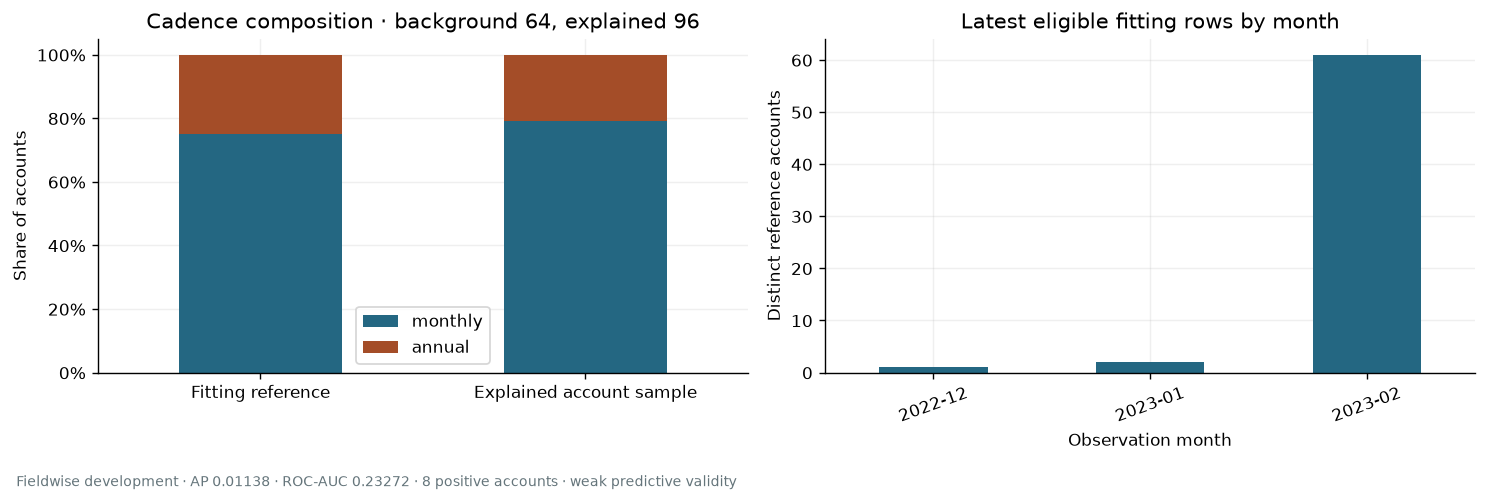

In [ ]:
if r:
    background = r["background"]
    display(pd.Series(background, name="Reference background").to_frame())
    cadence_mix = pd.DataFrame(
        {
            "Fitting reference": background["cadence"],
            "Explained account sample": r["reference_populations"]["explained_global"]["cadence"],
        }
    ).fillna(0)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    cadence_mix.div(cadence_mix.sum()).T.plot.bar(
        stacked=True,
        rot=0,
        color=cadence_colours,
        ax=axes[0],
        title="Cadence composition · background 64, explained 96",
        ylabel="Share of accounts",
    )
    axes[0].yaxis.set_major_formatter(PercentFormatter(1))
    pd.Series(background["month"]).plot.bar(
        color=blue,
        ax=axes[1],
        title="Latest eligible fitting rows by month",
        ylabel="Distinct reference accounts",
        xlabel="Observation month",
    )
    axes[1].tick_params(axis="x", labelrotation=20)
    show(fig)

## Additive attribution and compatibility gates

For a finite training background $B$, the block game's value is the
mean of the full predictor evaluated with the selected blocks from the
example and the remaining blocks from each row in $B$.
Shapley attribution averages the marginal change from adding a block
across all insertion orders. With $d$ blocks, the weight on a set of size $s$ is $1/[d\binom{d-1}{s}]$.

$$f(x)=\mathbb{E}_{b\in B}[f(b)]+\sum_j\phi_j(x).$$

In an illustrative clipped two-block game the four coalition values
for empty, A, B and A+B are 0, 3, 0 and 5. Contributions are 4 and 1.
Their sum plus the base is 5. The example uses the clipped prediction
at each coalition. The research reports actual residuals separately.

Interventional TreeExplainer was checked on the frozen classifier in
raw margin and class-1 probability space with the fitted column order.
Keep the two decompositions separate. The primary result uses
probability. The raw-feature block game is a separate finite reference
calculation on the full probability callable. Its blocks combine
episode history, billing and contract, and product usage with coverage.

,rows,tolerance,max_abs_error,mean_abs_error,failures,coefficient_shape,base_shape,reference_base_max_error,supported,seconds,explained_output,perturbation
raw,12,0.0,0.0,0.0,0,"[12, 30]",[12],0.0,True,0.109219,class-1 log odds,interventional
final,12,0.0,0.0,0.0,0,"[12, 30]",[12],0.0,True,0.041134,class-1 probability,interventional


,rows,tolerance,max_abs_error,mean_abs_error,failures
Primary final output,98.0,1.000000e-08,2.512940e-09,5.066178e-10,0.0
Finite-background block game,98.0,1.000000e-08,1.110223e-16,1.959972e-17,0.0
Tree raw,98.0,1.000000e-07,4.205374e-08,1.484865e-08,0.0
Tree final,98.0,1.000000e-08,2.512940e-09,5.066178e-10,0.0


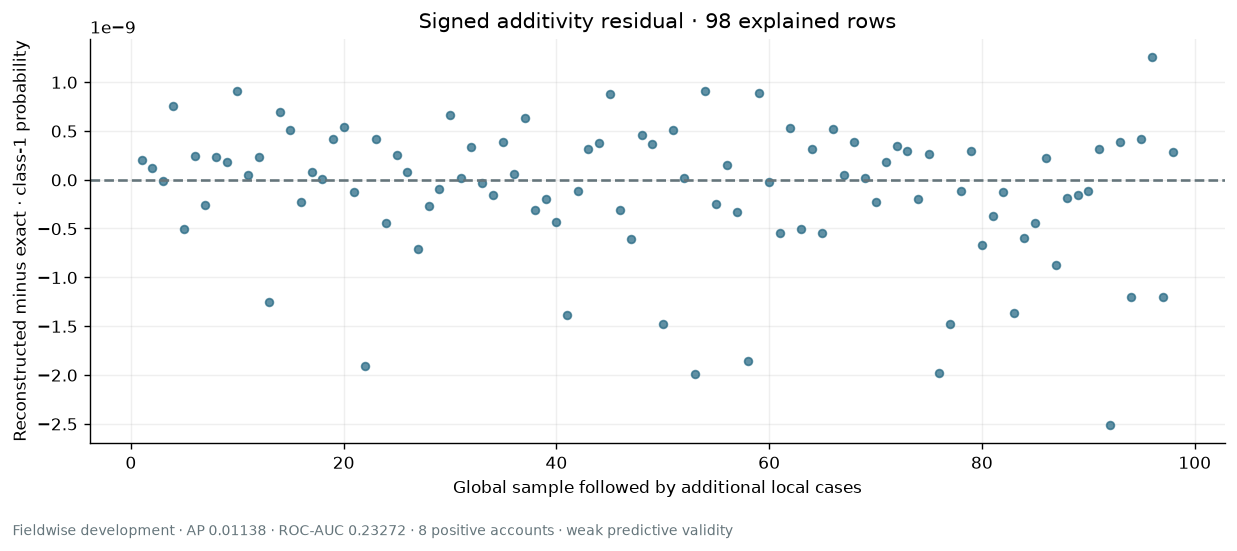

In [ ]:
if r:
    compatibility = pd.DataFrame(r["compatibility"]["tree"]).T
    display(compatibility)
    primary = r["primary"]
    checks = {
        "Primary final output": primary["reconciliation"],
        "Finite-background block game": r["grouped_game"]["reconciliation"],
    }
    checks.update(
        {
            f"Tree {name}": evidence["original"]["reconciliation"]
            for name, evidence in r["tree_explanations"].items()
            if "original" in evidence
        }
    )
    display(pd.DataFrame(checks).T)
    residual = np.asarray(primary["base"]) + np.asarray(primary["values"]).sum(axis=1)
    residual -= np.asarray(primary["predictions"])
    fig, ax = plt.subplots()
    ax.scatter(range(1, len(residual) + 1), residual, s=20, color=blue, alpha=0.72)
    ax.axhline(0, color=grey, ls="--")
    ax.set(
        title=f"Signed additivity residual · {len(residual)} explained rows",
        xlabel="Global sample followed by additional local cases",
        ylabel=f"Reconstructed minus exact · {primary['scale']}",
    )
    show(fig)

## Global reliance and the permutation limit

The mean absolute probability contribution ranks behaviour over
96 accounts. Original-feature totals are signed sums of their
transformed components before taking magnitudes. A separate
block game shows the joint model response when correlated fields
travel together. The raw and probability summaries answer questions
in different units.

Performance permutation would compare a scoring metric before and
after feature disruption, with outcome and row alignment preserved.
Eight positive accounts and weak AP/ROC-AUC make a churn performance
ranking unreliable. This study uses contribution and supported
sensitivity evidence for diagnosis.

,Mean absolute contribution
episode_age_days,0.117810
latest_sessions,0.018161
expected_usage_months,0.014779
days_since_last_invoice,0.011247
mean_active_users,0.010646
max_active_users,0.007980
active_users_change,0.007232
mean_events,0.005882
events_change,0.004692
latest_active_users,0.004194


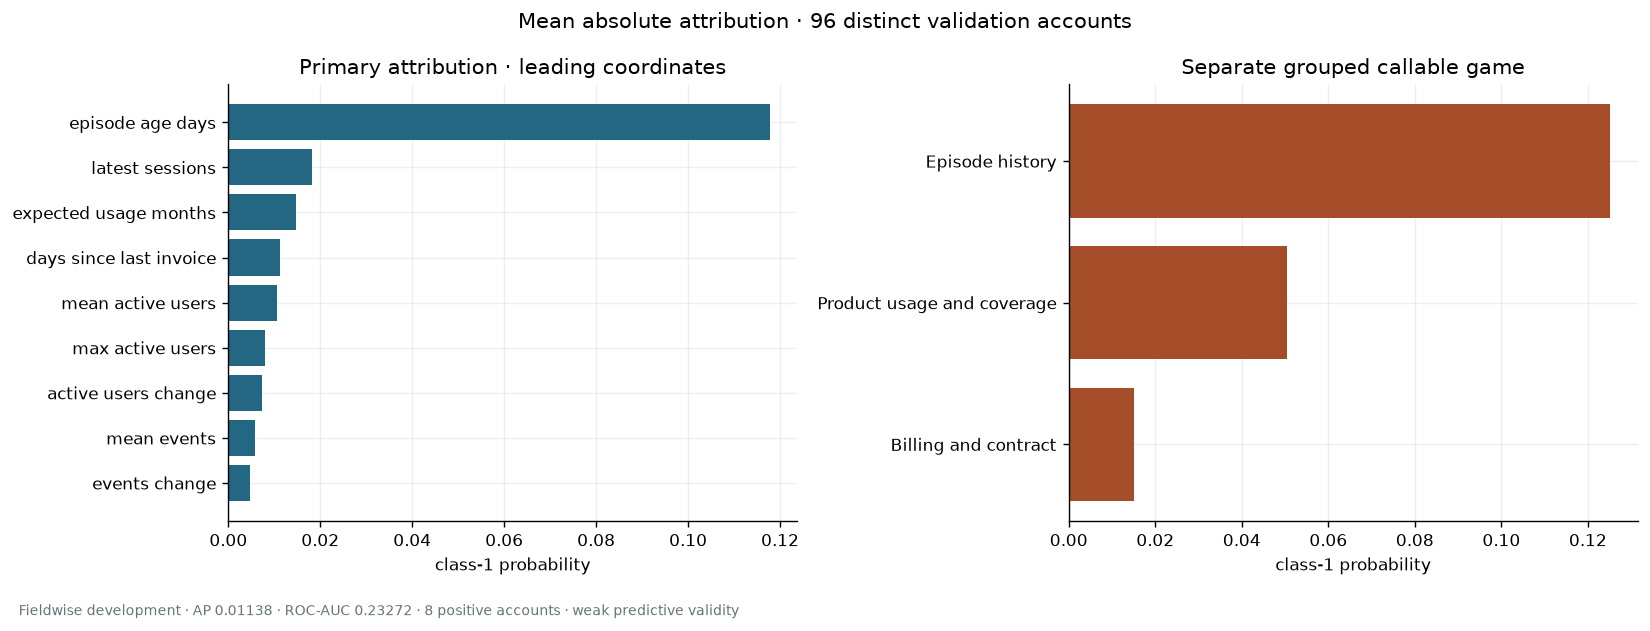

**episode age days** has the largest average magnitude (0.1178 on this scale). The ranking describes this model and reference population.

In [ ]:
if r:
    n_global = r["global_rows"]
    ranked = pd.Series(r["global"]["mean_absolute"]).sort_values(ascending=False)
    block = pd.Series(r["grouped_global"]["mean_absolute"]).sort_values(ascending=True)
    display(ranked.rename("Mean absolute contribution").to_frame())
    fig, axes = plt.subplots(1, 2, figsize=(13.3, 5))
    shown = ranked.head(9).sort_values()
    axes[0].barh([readable(x) for x in shown.index], shown, color=blue)
    axes[0].set(title="Primary attribution · leading coordinates", xlabel=primary["scale"])
    axes[1].barh(block.index, block, color=warm)
    axes[1].set(title="Separate grouped callable game", xlabel=r["grouped_game"]["scale"])
    fig.suptitle(f"Mean absolute attribution · {n_global} distinct validation accounts")
    show(fig)
    display(
        Markdown(
            f"**{readable(ranked.index[0])}** has the largest average magnitude "
            f"({ranked.iloc[0]:.4g} on this scale). "
            "The ranking describes this model and reference population."
        )
    )

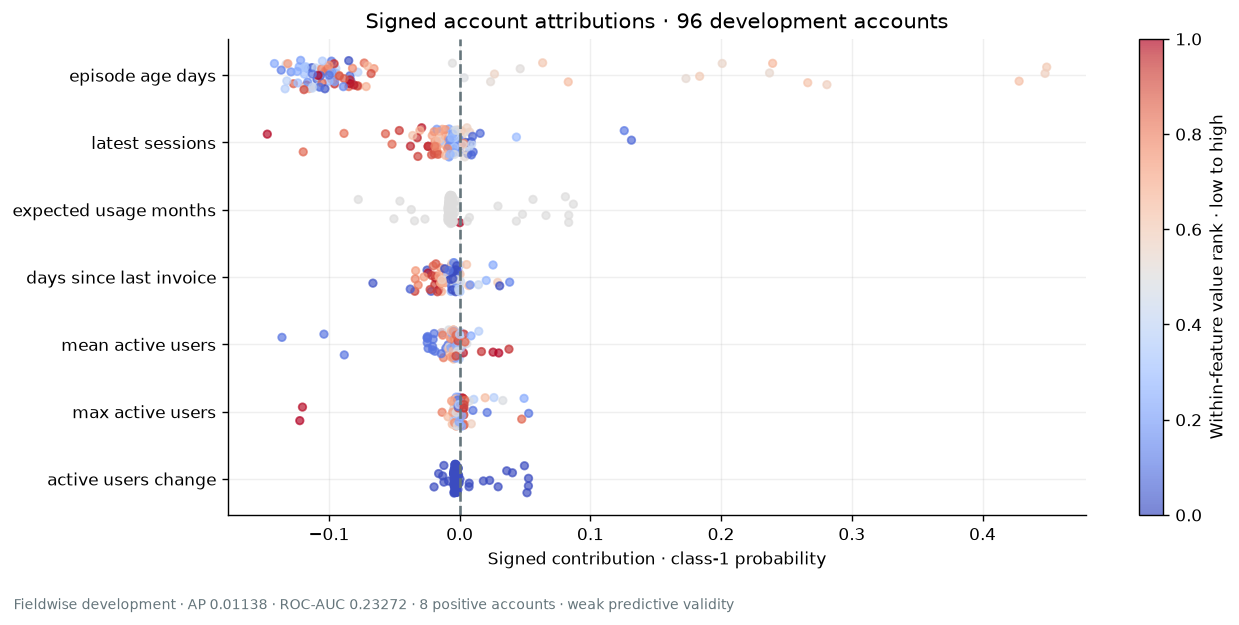

,accounts
annual,20
monthly,76


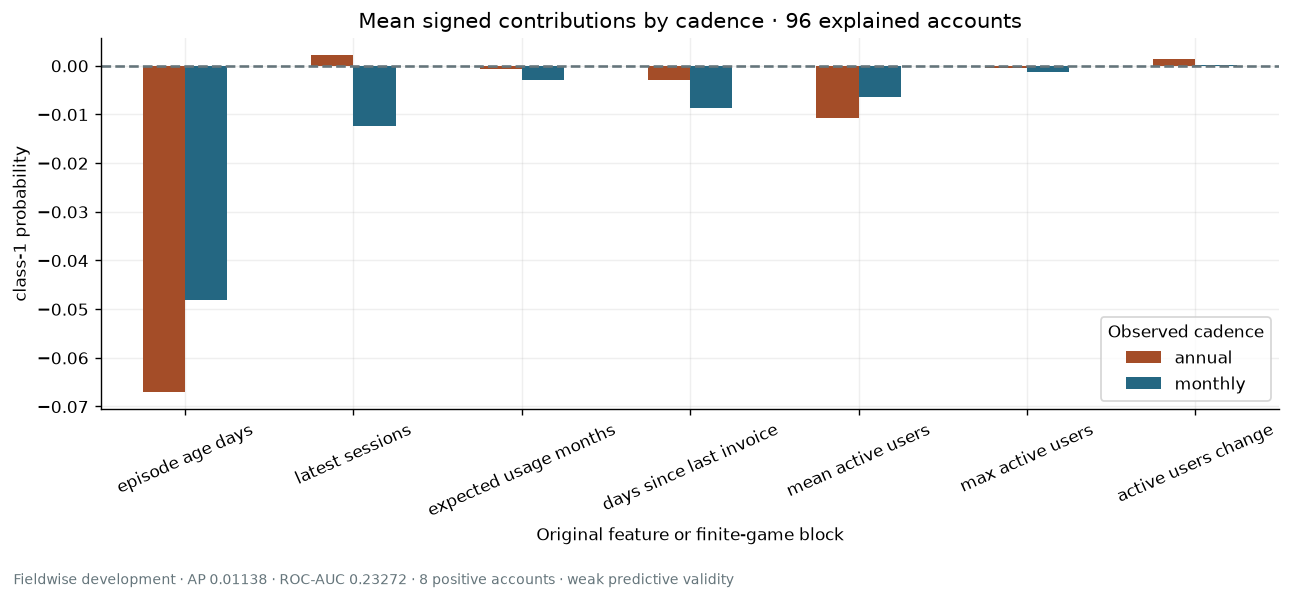

In [ ]:
if r:
    points = pd.DataFrame(primary["values"], columns=primary["columns"]).iloc[:n_global]
    originals = pd.DataFrame(r["feature_values"]).iloc[:n_global]
    leading = ranked.head(7).index
    fig, ax = plt.subplots(figsize=(10.6, 5))
    jitter = np.random.default_rng(31)
    for position, name in enumerate(reversed(leading)):
        if name in originals and pd.api.types.is_numeric_dtype(originals[name]):
            colour = originals[name].rank(pct=True).fillna(-0.1)
        else:
            colour = np.full(len(points), 0.5)
        artist = ax.scatter(
            points[name],
            position + jitter.uniform(-0.22, 0.22, len(points)),
            c=colour,
            cmap="coolwarm",
            vmin=0,
            vmax=1,
            s=19,
            alpha=0.68,
        )
    ax.axvline(0, color=grey, ls="--")
    ax.set(
        title=f"Signed account attributions · {n_global} development accounts",
        xlabel=f"Signed contribution · {primary['scale']}",
        yticks=range(len(leading)),
        yticklabels=[readable(x) for x in reversed(leading)],
    )
    if model == "churn":
        fig.colorbar(artist, ax=ax, label="Within-feature value rank · low to high")
    show(fig)

    cadence = pd.DataFrame(
        {name: row["mean_signed"] for name, row in r["global"]["cadences"].items()}
    ).loc[leading]
    display(pd.DataFrame(r["global"]["cadences"]).T[["accounts"]])
    fig, ax = plt.subplots(figsize=(10.5, 4.8))
    cadence.rename(index=readable).plot.bar(ax=ax, color=cadence_colours, rot=24)
    ax.axhline(0, color=grey, ls="--")
    ax.set(
        title=f"Mean signed contributions by cadence · {n_global} explained accounts",
        xlabel="Original feature or finite-game block",
        ylabel=primary["scale"],
    )
    ax.legend(title="Observed cadence")
    show(fig)

## Attribution dependence and synthetic-pattern diagnostics

The dependence view holds the actual explained rows and uses episode
age as the horizontal coordinate. Large age contributions can reflect
training cohort or generator structure. An age effect in the model
gives no evidence of causal subscription ageing. These attribution
plots and an intervention-style sensitivity grid are different views.

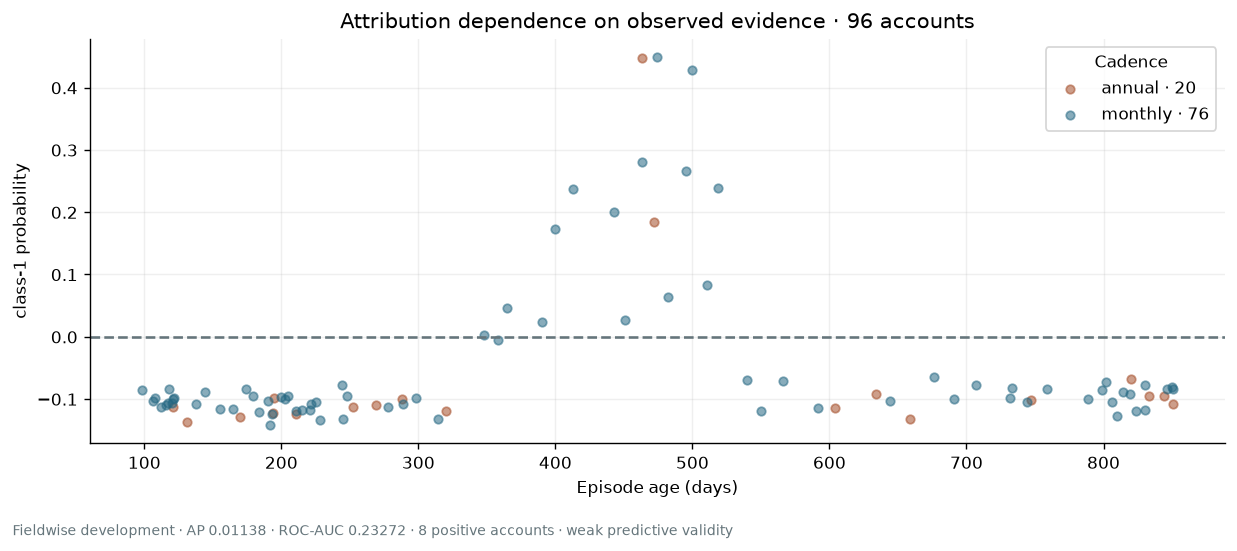

,rows,accounts,mean_prediction,mae
annual,157.0,43.0,0.049369,0.062007
monthly,560.0,162.0,0.073030,0.083659


In [ ]:
if r:
    name = "episode_age_days" if model == "churn" else "Invoice history and cadence"
    field = "episode_age_days" if model == "churn" else "issued_gbp"
    key = "billing_frequency" if model == "churn" else "cadence"
    fig, ax = plt.subplots()
    if name in points:
        for level, group in originals.groupby(key):
            ax.scatter(
                group[field],
                points.loc[group.index, name],
                s=24,
                alpha=0.54,
                color=cadence_colours.get(level, grey),
                label=f"{level} · {len(group)}",
            )
    ax.axhline(0, color=grey, ls="--")
    ax.set(
        title=f"Attribution dependence on observed evidence · {n_global} accounts",
        xlabel="Episode age (days)" if model == "churn" else "Historical gross issued GBP",
        ylabel=primary["scale"],
    )
    if name in points:
        ax.legend(title="Cadence")
    show(fig)

    display(pd.DataFrame(r["validation_cadence"]).T)

## Local cases and additive reconstruction

Case roles were fixed before attribution. Ties use retained observation
order and roles draw distinct accounts. The tables show the exact
model output and recorded outcome together. A waterfall starts from
the background mean, adds each signed term, and ends at the explained
prediction. The signed error remains separate from the decomposition.

Read the confirmed-positive, high-score false positive, low-score
true negative and near-threshold examples as diagnostics. An
individual false-positive breakdown can be mathematically accurate
even when the model's probability ranking is poor.

In [ ]:
if r:
    case_rows = pd.DataFrame(r["cases"])
    case_rows["base"] = case_rows.position.map(lambda pos: primary["base"][pos])
    case_rows["base plus contributions"] = case_rows.position.map(
        lambda pos: primary["base"][pos] + sum(primary["values"][pos])
    )
    display(case_rows.drop(columns="position").round(9))
    if model == "churn" and "original" in r["tree_explanations"].get("raw", {}):
        margin = r["tree_explanations"]["raw"]["original"]
        display(
            pd.DataFrame(
                [
                    {
                        "Case": row["anonymous"],
                        "Log-odds base": margin["base"][row["position"]],
                        "Signed log-odds sum": sum(margin["values"][row["position"]]),
                        "Class-1 margin": row["raw"],
                        "Probability": row["final"],
                    }
                    for row in r["cases"]
                ]
            )
        )

,label,anonymous,cadence,month,actual,final,raw,signed_error,base,base plus contributions
0,confirmed positive near positive median,Case 01,monthly,2023-04,1.0,0.003965,-5.526204,-0.996035,0.156422,0.003965
1,high score false positive,Case 02,monthly,2023-06,0.0,0.919054,2.429564,0.919054,0.156422,0.919054
2,low score true negative,Case 03,monthly,2023-07,0.0,0.002711,-5.907698,0.002711,0.156422,0.002711
3,near the research threshold,Case 04,monthly,2023-04,0.0,0.003965,-5.526204,0.003965,0.156422,0.003965


,Case,Log-odds base,Signed log-odds sum,Class-1 margin,Probability
0,Case 01,-3.685443,-1.840762,-5.526204,0.003965
1,Case 02,-3.685443,6.115007,2.429564,0.919054
2,Case 03,-3.685443,-2.222255,-5.907698,0.002711
3,Case 04,-3.685443,-1.840762,-5.526204,0.003965


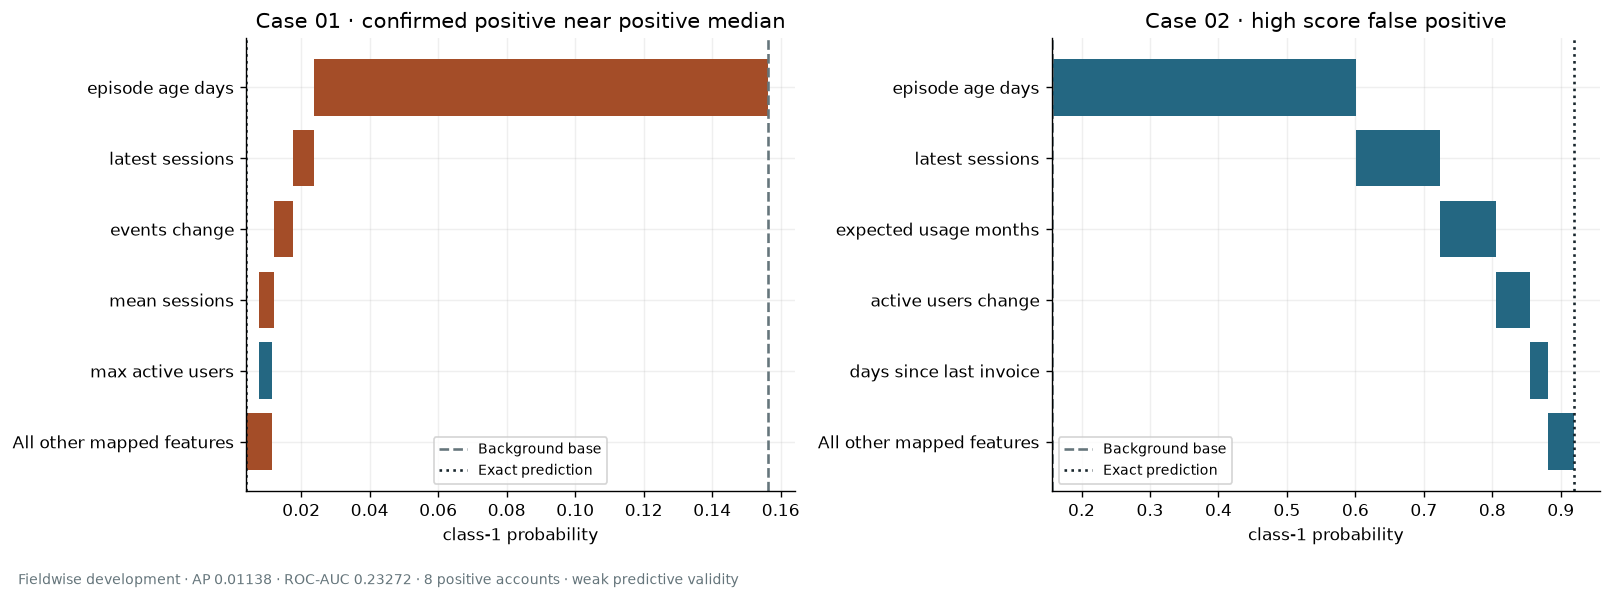

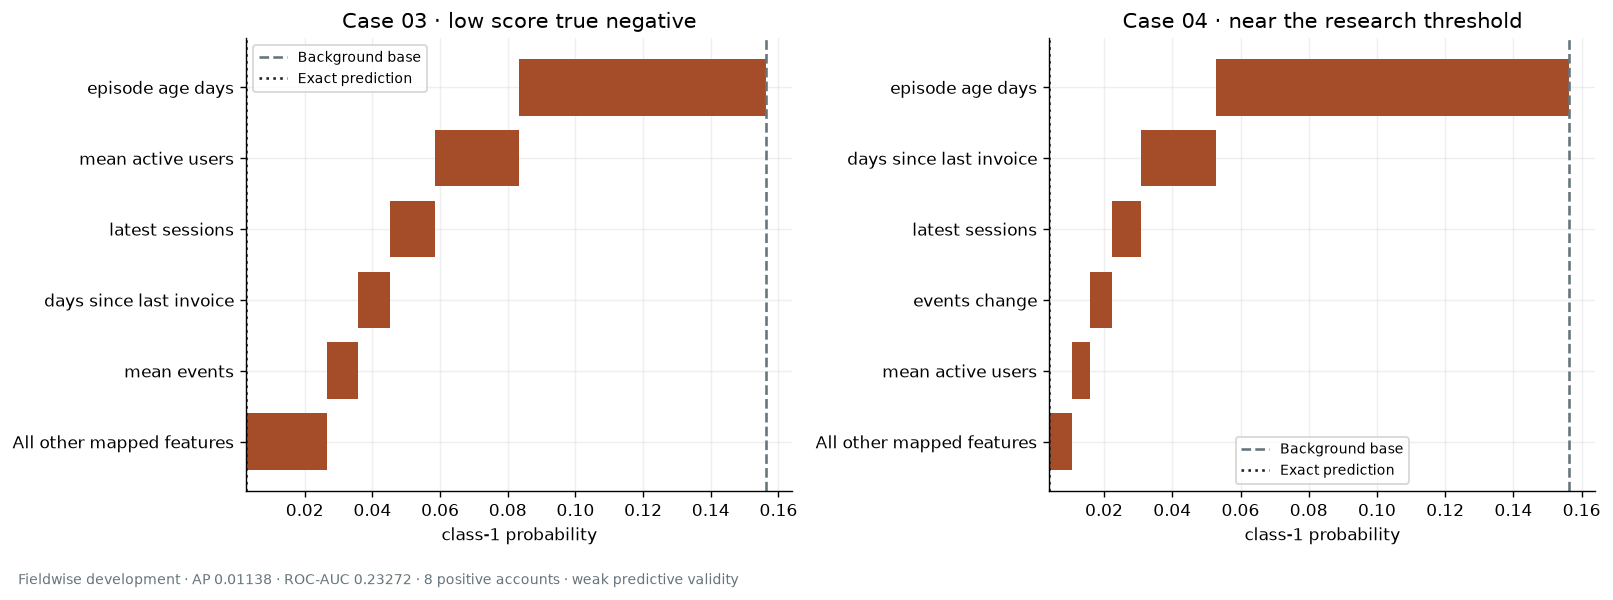

In [ ]:
def waterfall(ax, case, evidence):
    pos = case["position"]
    values = pd.Series(evidence["values"][pos], index=evidence["columns"])
    order = values.abs().sort_values(ascending=False).index
    shown = values.loc[order[:5]]
    if len(order) > 5:
        shown = pd.concat(
            [shown, pd.Series({"All other mapped features": values.loc[order[5:]].sum()})]
        )
    labels = [readable(name) for name in shown.index]
    base = evidence["base"][pos]
    start = base + np.r_[0, np.cumsum(shown.to_numpy())[:-1]]
    end = start + shown.to_numpy()
    ax.barh(
        labels,
        np.abs(shown.to_numpy()),
        left=np.minimum(start, end),
        color=np.where(shown.to_numpy() >= 0, blue, warm),
    )
    ax.axvline(base, color=grey, ls="--", label="Background base")
    ax.axvline(case["final"], color="#17252c", ls=":", label="Exact prediction")
    ax.set(title=f"{case['anonymous']} · {case['label']}", xlabel=evidence["scale"])
    ax.invert_yaxis()
    ax.legend(loc="best", fontsize=8)


if r:
    for start in range(0, len(r["cases"]), 2):
        selected = r["cases"][start : start + 2]
        fig, axes = plt.subplots(1, len(selected), figsize=(13, 4.8), squeeze=False)
        for axis, case in zip(axes[0], selected, strict=True):
            waterfall(axis, case, primary)
        show(fig)

## Supported partial dependence and individual conditional expectation

An ICE line evaluates $f(x_{-j}^{(i)},z)$ for one case at a supported
value $z$. The displayed PDP is the mean over supported validation
accounts at each grid point. The set of supported accounts can change.
A training-support check uses observed cadence and distance in a set of
relevant companion variables. The predeclared local radius is 0.30
training IQR units under maximum coordinate distance. The display requires
at least five accounts for a global point.

For two supported ICE predictions of 40 and 60, their descriptive PDP
value is 50. This changes supplied predictors in the model. Real-world
interventions would require separate evidence about feasible changes.

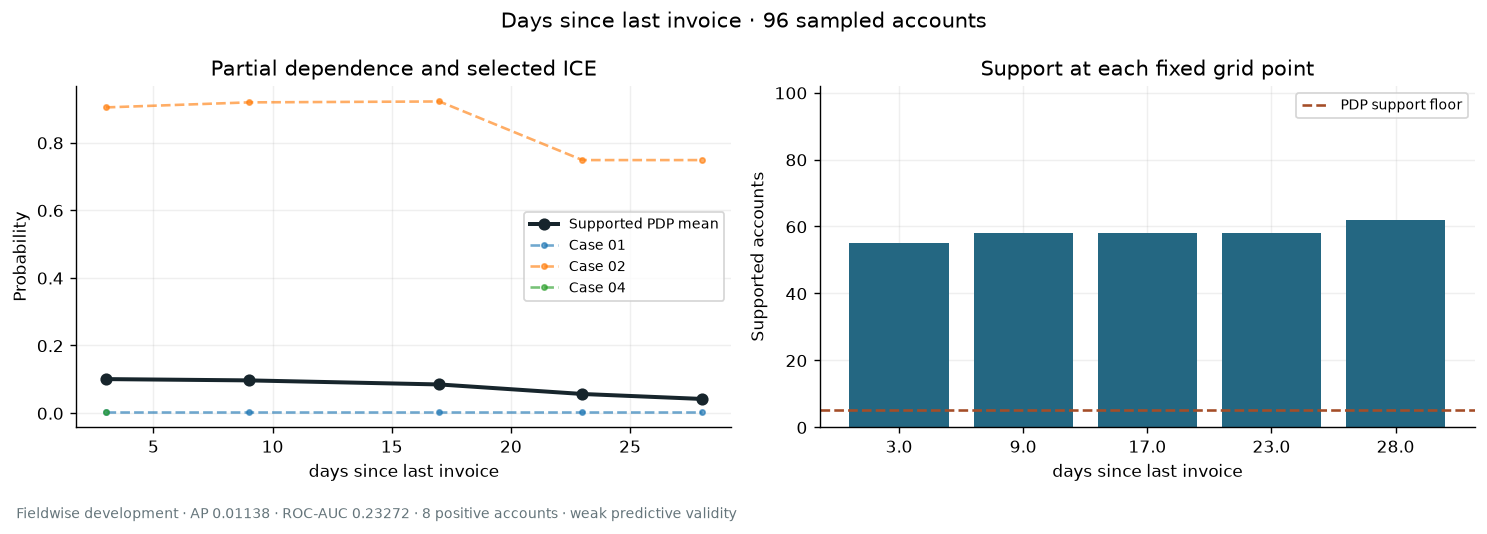

**5 of 5** points meet the support floor for days since last invoice. Interpret changes with the support counts, since accounts may differ across points.

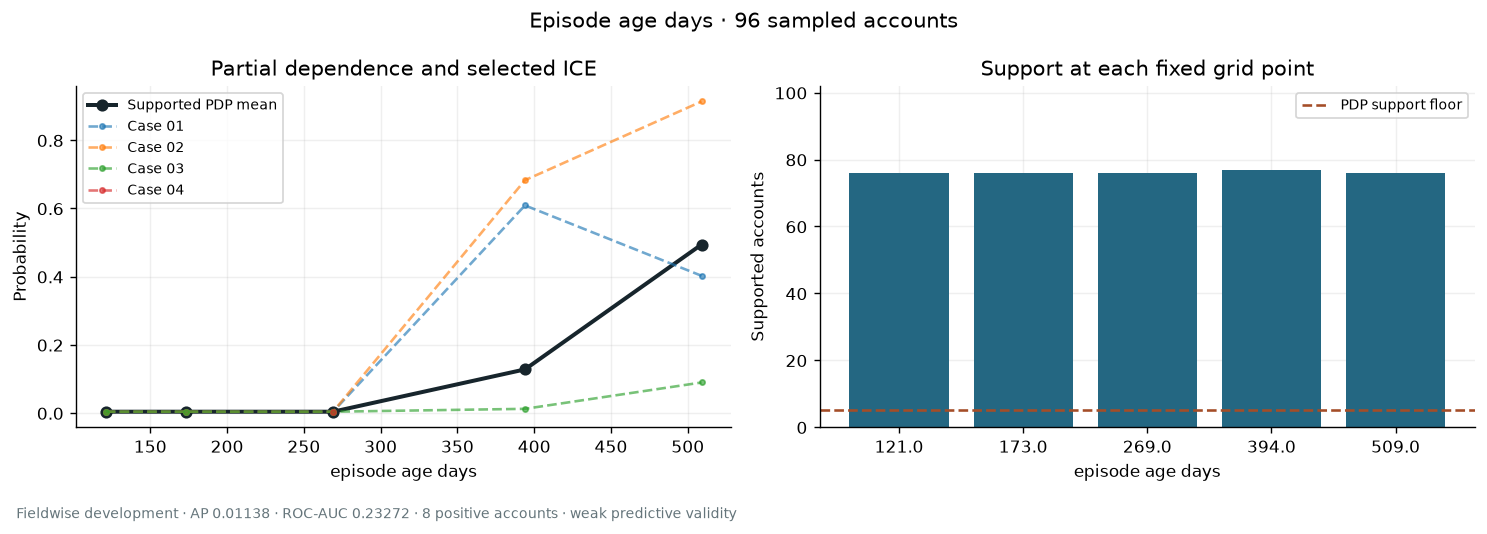

**5 of 5** points meet the support floor for episode age days. Interpret changes with the support counts, since accounts may differ across points.

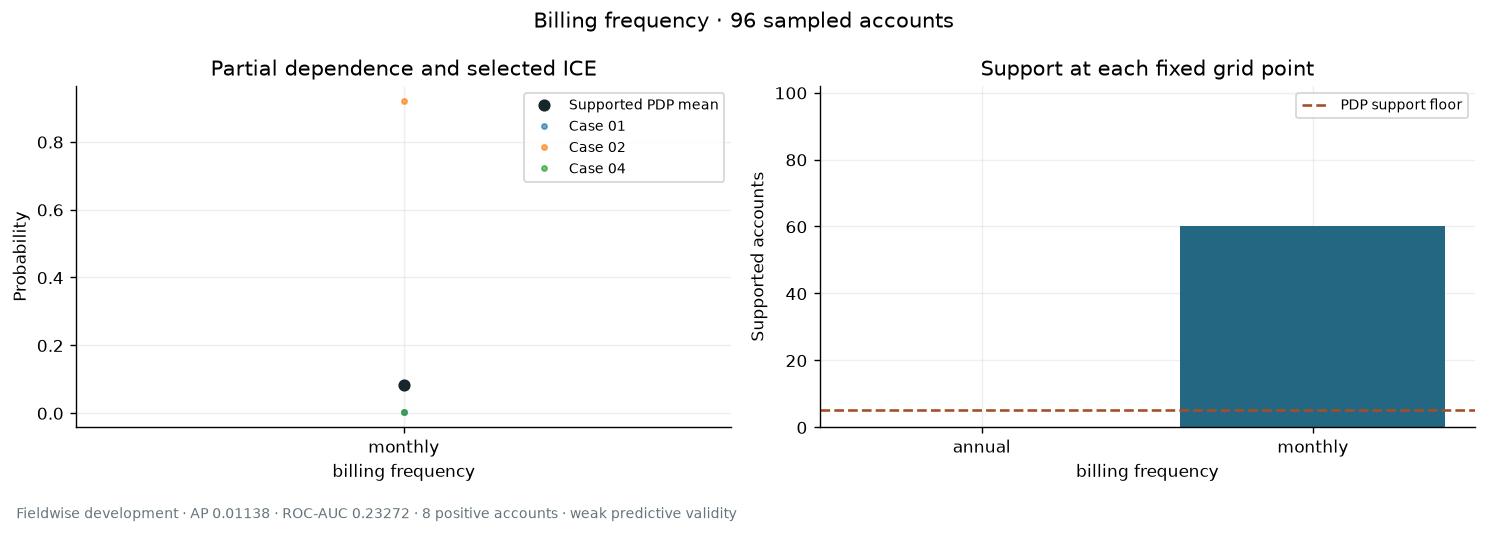

**1 of 2** points meet the support floor for billing frequency. Interpret changes with the support counts, since accounts may differ across points.

In [ ]:
if r:
    for name, entry in r["sensitivity"]["curves"].items():
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
        grid = entry["grid"]
        field_is_category = isinstance(grid[0], str)
        axes[0].plot(
            grid,
            entry["pdp"],
            "o" if field_is_category else "o-",
            color="#17252c",
            label="Supported PDP mean",
            lw=2.3,
        )
        for case, values in entry["ice"].items():
            if any(value is not None for value in values):
                short = next(row["anonymous"] for row in r["cases"] if row["label"] == case)
                axes[0].plot(
                    grid, values, "." if field_is_category else ".--", alpha=0.64, label=short
                )
        axes[0].set(
            title="Partial dependence and selected ICE", ylabel=units, xlabel=readable(name)
        )
        axes[0].legend(fontsize=8)
        axes[1].bar(range(len(grid)), entry["support"], color=blue)
        axes[1].axhline(5, color=warm, ls="--", label="PDP support floor")
        axes[1].set(
            title="Support at each fixed grid point",
            xlabel=readable(name),
            ylabel="Supported accounts",
            xticks=range(len(grid)),
            xticklabels=grid,
            ylim=(0, entry["candidate_accounts"] + 6),
        )
        axes[1].legend(fontsize=8)
        fig.suptitle(
            f"{readable(name).capitalize()} · {entry['candidate_accounts']} sampled accounts"
        )
        show(fig)
        display(
            Markdown(
                f"**{sum(value is not None for value in entry['pdp'])} of {len(grid)}** points "
                f"meet the support floor for {readable(name)}. Interpret changes with the "
                "support counts, since accounts may differ across points."
            )
        )

## Observed-support interaction diagnostics

For frozen pairs, display jointly supported predictions on the fixed
grid. A two-by-two interaction contrast is
$f_{11}-f_{10}-f_{01}+f_{00}$ on the same accounts. At least five
accounts must support all corners, so four individually supported
marginal means cannot substitute for this check. Blank values mark
unsupported cells. This screens out misleading pairwise inferences.

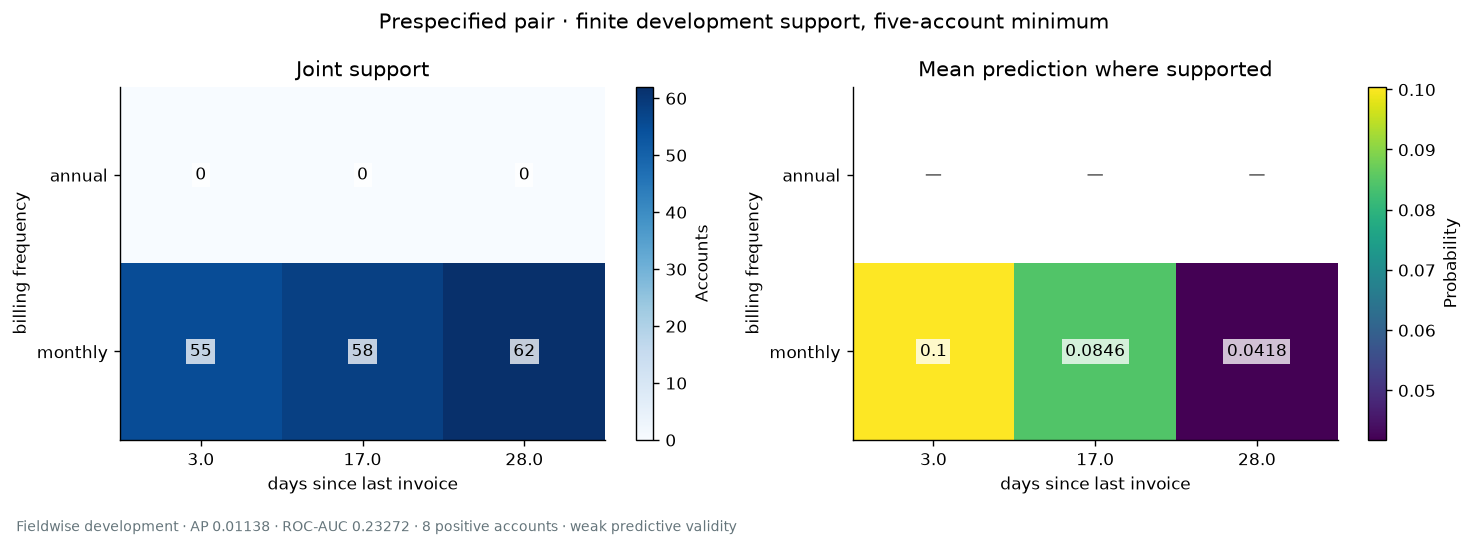

,x,y,Accounts with all four corners,effect
0,"[3.0, 17.0]","[annual, monthly]",0,None
1,"[17.0, 28.0]","[annual, monthly]",0,None


**Matched contrasts meeting support:** 0.

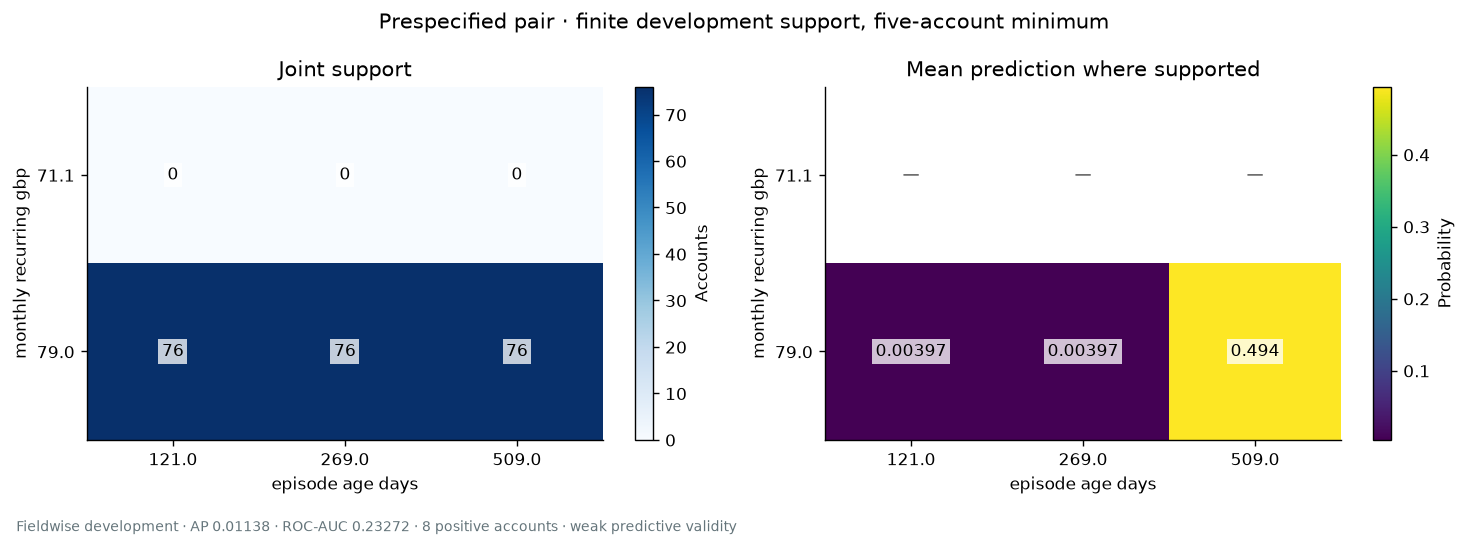

,x,y,Accounts with all four corners,effect
0,"[121.0, 269.0]","[71.1, 79.0]",0,None
1,"[269.0, 509.0]","[71.1, 79.0]",0,None


**Matched contrasts meeting support:** 0.

In [ ]:
if r:
    for entry in r["sensitivity"]["interactions"]:
        values = np.asarray(entry["surface"], dtype=float)
        counts = np.asarray(entry["support"])
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
        for data, title, palette in (
            (counts, "Joint support", "Blues"),
            (values, "Mean prediction where supported", "viridis"),
        ):
            ax = axes[0] if title == "Joint support" else axes[1]
            image = ax.imshow(data, cmap=palette, aspect="auto")
            for (i, j), value in np.ndenumerate(data):
                ax.text(
                    j,
                    i,
                    f"{value:.3g}" if np.isfinite(value) else "—",
                    ha="center",
                    va="center",
                    color="black",
                    bbox={"facecolor": "white", "alpha": 0.76, "pad": 2, "edgecolor": "none"},
                )
            ax.grid(False)
            x, y = entry["features"]
            ax.set(
                title=title,
                xlabel=readable(x),
                ylabel=readable(y),
                xticks=range(len(entry["x"])),
                xticklabels=entry["x"],
                yticks=range(len(entry["y"])),
                yticklabels=entry["y"],
            )
            fig.colorbar(image, ax=ax, label="Accounts" if title == "Joint support" else units)
        fig.suptitle("Prespecified pair · finite development support, five-account minimum")
        show(fig)
        matched = pd.DataFrame(entry["matched_contrasts"])
        if not matched.empty:
            display(matched.rename(columns={"matched": "Accounts with all four corners"}))
        supported = sum(row["effect"] is not None for row in entry["matched_contrasts"])
        display(Markdown(f"**Matched contrasts meeting support:** {supported}."))

## Stability, replay and background sensitivity

Identical background and model inputs are replayed first. Then each
frozen alternate background is compared with the primary signed
decomposition. Global rank summaries use tied-rank Spearman and
top-set Jaccard overlap. Account resampling uses 100 bootstrap draws
from one explained row per account. The underlying estimator is held
fixed. Local variation across backgrounds measures explanation
dependence on the reference population. Predictive error uncertainty
and model generalisation require separate evidence.

Rank comparisons use mean absolute attribution on 96 validation
accounts. Background comparisons hold those accounts fixed. Each
bootstrap resamples 96 account representatives with replacement
at fixed background. The reported maximum reference-driven shift
is across all explained rows and all contribution columns.

,spearman,top_jaccard,compared,diagnostic_floors_met
account_bootstrap,0.994972,1.0,100,True
background,0.983912,1.0,4,True


,Seed,Accounts,Billing mix,Available,Rank correlation,Base shift,Largest local movement
0,910,64,"{'monthly': 48, 'annual': 16}",True,0.986928,-0.048459,0.038417
1,911,64,"{'monthly': 48, 'annual': 16}",True,0.983912,-0.037922,0.036109
2,909,32,"{'monthly': 24, 'annual': 8}",True,0.980895,0.043979,0.048954
3,909,128,"{'monthly': 97, 'annual': 31}",True,0.983912,-0.086611,0.072248


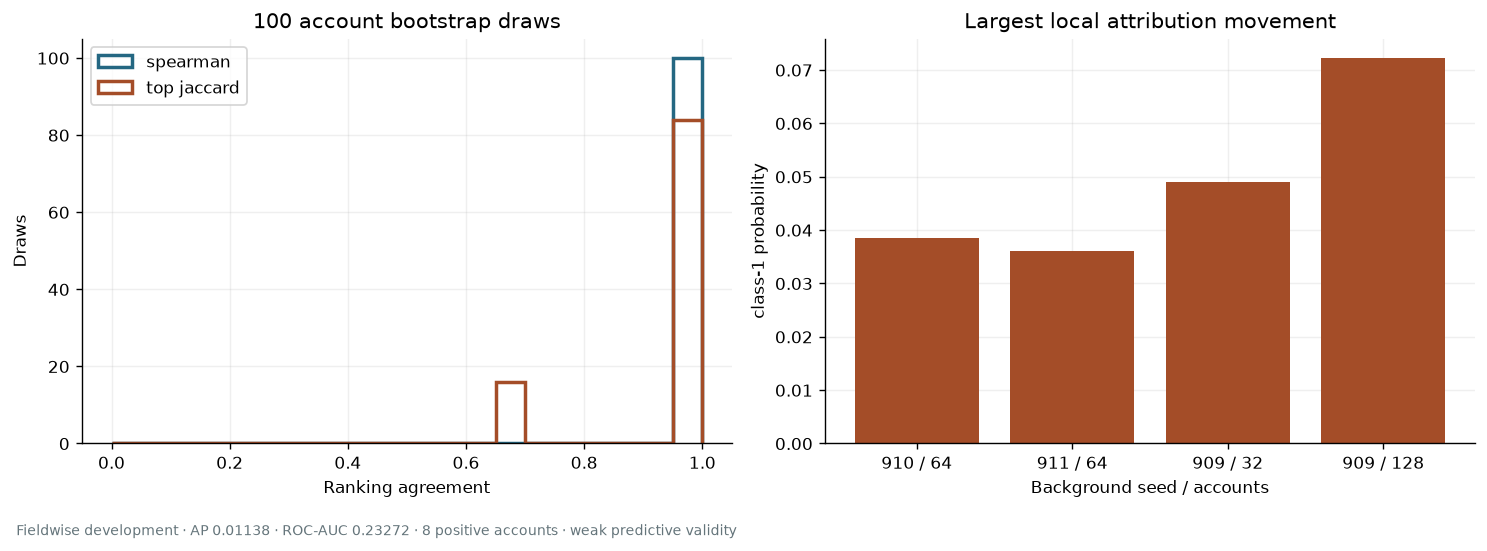

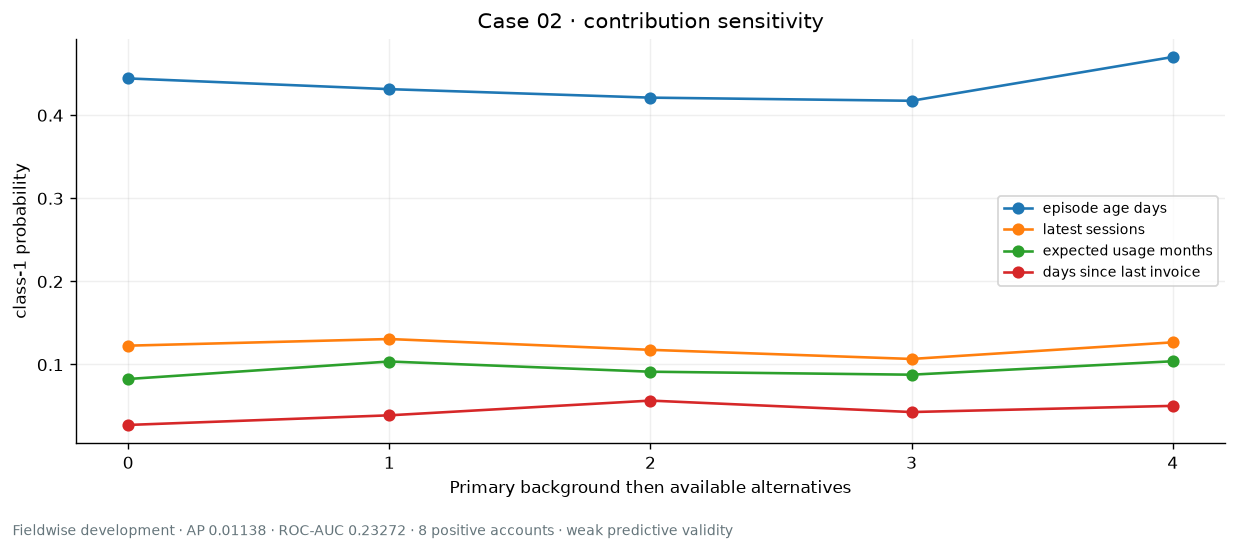

Identical-background replay maximum absolute change **0** on this scale. Alternative reference cohorts can change the local baseline and contributions.

,Case,Largest-spread term,Signed span,Sign crosses zero,Near-zero run present,Backgrounds
0,Case 01,episode age days,0.095979,False,False,5
1,Case 02,episode age days,0.052683,False,False,5
2,Case 03,episode age days,0.065400,False,False,5
3,Case 04,episode age days,0.075580,False,False,5


In [ ]:
if r:
    stability = r["stability"]
    summary = pd.DataFrame(stability["summary"]).T
    display(summary)
    bg = pd.DataFrame(
        [
            {
                "Seed": row["background"]["seed"],
                "Accounts": row["background"]["accounts"],
                "Billing mix": row["background"]["cadence"],
                "Available": row["available"],
                "Rank correlation": row.get("global", {}).get("spearman"),
                "Base shift": row.get("base_shift"),
                "Largest local movement": row.get("maximum_local_abs_change"),
            }
            for row in stability["background_comparisons"]
        ]
    )
    display(bg)
    sampling = pd.DataFrame(stability["sampling"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
    for name, hue in (("spearman", blue), ("top_jaccard", warm)):
        axes[0].hist(
            sampling[name].dropna(),
            bins=np.linspace(0, 1, 21),
            histtype="step",
            lw=2,
            color=hue,
            label=readable(name),
        )
    axes[0].set(title="100 account bootstrap draws", xlabel="Ranking agreement", ylabel="Draws")
    axes[0].legend()
    series = bg["Seed"].astype(str) + " / " + bg["Accounts"].astype(str)
    axes[1].bar(series, bg["Largest local movement"], color=warm)
    axes[1].set(
        title="Largest local attribution movement",
        xlabel="Background seed / accounts",
        ylabel=primary["scale"],
    )
    show(fig)

    demonstration = r["cases"][1]
    small = pd.DataFrame(
        stability["local_values"][demonstration["label"]], columns=primary["columns"]
    )[ranked.head(4).index]
    fig, ax = plt.subplots()
    small.rename(columns=readable).plot(marker="o", ax=ax)
    ax.set(
        title=f"{demonstration['anonymous']} · contribution sensitivity",
        xlabel="Primary background then available alternatives",
        ylabel=primary["scale"],
        xticks=range(len(small)),
    )
    ax.legend(fontsize=8)
    show(fig)
    display(
        Markdown(
            f"Identical-background replay maximum absolute change "
            f"**{stability['replay_max_abs_delta']:.3g}** on this scale. "
            "Alternative reference cohorts can change the local baseline and contributions."
        )
    )
    scale_floor = primary["reconciliation"]["tolerance"]
    local_summary = []
    for case in r["cases"]:
        repeated = np.asarray(stability["local_values"][case["label"]])
        spread = np.ptp(repeated, axis=0)
        index = int(np.argmax(spread))
        above = repeated[:, index] > scale_floor
        below = repeated[:, index] < -scale_floor
        local_summary.append(
            {
                "Case": case["anonymous"],
                "Largest-spread term": readable(primary["columns"][index]),
                "Signed span": float(spread[index]),
                "Sign crosses zero": bool(above.any() and below.any()),
                "Near-zero run present": bool((~(above | below)).any()),
                "Backgrounds": len(repeated),
            }
        )
    display(pd.DataFrame(local_summary))

## Feature correlation and interpretation limits

Spearman correlation describes monotone associations on the validation
rows. It is descriptive, and repeated account observations contribute
more than one row in this view. Correlated invoice predictors can share
attribution and offer substitutes during singleton permutation. Tree
and grouped callable explanations each use a specified background;
correlated hybrids can occur even when related inputs are moved jointly.

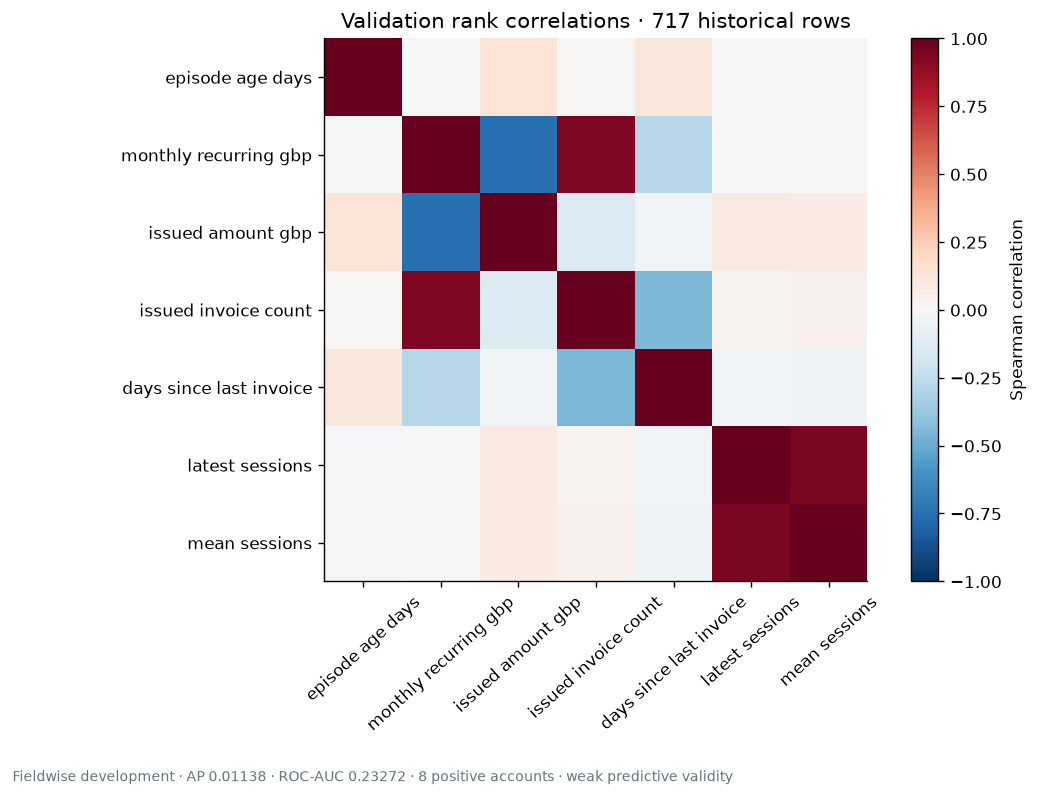

In [ ]:
if r:
    selected = (
        [
            "episode_age_days",
            "monthly_recurring_gbp",
            "issued_amount_gbp",
            "issued_invoice_count",
            "days_since_last_invoice",
            "latest_sessions",
            "mean_sessions",
        ]
        if model == "churn"
        else [
            "issued_gbp",
            "recent_gbp",
            "invoice_count",
            "recency_days",
            "mean_invoice_gbp",
            "snapshot_gbp",
            "tenure_days",
        ]
    )
    corr = pd.DataFrame(r["rank_correlations"]).loc[selected, selected]
    fig, ax = plt.subplots(figsize=(8.5, 6.4))
    image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1, aspect="equal")
    labels = [readable(name) for name in corr.index]
    ax.set(
        title=f"Validation rank correlations · {len(dist)} historical rows",
        xticks=range(len(labels)),
        xticklabels=labels,
        yticks=range(len(labels)),
        yticklabels=labels,
    )
    ax.tick_params(axis="x", labelrotation=42)
    ax.grid(False)
    fig.colorbar(image, ax=ax, label="Spearman correlation")
    show(fig)

## Scientific assessment

Episode age supplies the strongest average probability contribution
on the explained sample. Product usage and its coverage also affect
the frozen score. Within each training and validation window, these
features may reflect synthetic lifecycle and reporting patterns.
The accepted classifier's AP is close to prevalence, ROC-AUC is
below 0.5 and the threshold produces many false alerts. The
score decomposition supports engineering diagnosis. Causal drivers,
operational risk bands and retention recommendations remain outside
this evidence. The protected holdout stays unscored.

## Reproduction

The notebook reads the frozen protocol, manifest and selected report
from the Phase 09 workspace. The research runner validates model and
input fingerprints prior to masked predictions and writes all outputs
outside Git. Execute the repository source through a temporary review
copy in a fresh kernel. [Notebook instructions](../README.md).